# Validating the Dynamic Minimum-VaR Strategy

`dynamic-portfolio.ipynb` showed that a monthly re-optimised GARCH minimum-VaR portfolio had the lowest risk of five strategies over 2018–2025. That is one test period and a small set of comparisons. This notebook asks whether the result holds up under four tests:

| Test | Question | Viable if… |
|:--|:--|:--|
| **1. Stronger benchmarks** | Does the GARCH machinery add anything over simple rules: equal weight, inverse volatility, sample minimum variance, and the same min-VaR optimiser fed with a sample covariance? Does adding **DCC-GARCH** time-varying correlations help? | dynamic GARCH has lower risk than the simple rules after costs |
| **2. Calibrated tail** | Can the portfolio VaR be made accurate? This replaces the weighted-ν Student-t quantile with **filtered historical simulation (FHS)**. | the FHS VaR passes Kupiec and Christoffersen |
| **3. Walk-forward** | Does the result hold in many periods, not just 2018–2025? | dynamic GARCH wins on risk in most rolling 3-year windows |
| **4. Significance** | Are the differences larger than chance? This uses a paired block bootstrap. | the confidence interval for the risk reduction excludes zero |

**Evaluation period.** All rebalanced strategies run continuously from **January 2011 to December 2025**. This leaves at least three years of history (from Sept 2007) for the first estimates. Results are also reported for 2018–2025 to link back to Stages 3 and 5.

**Static portfolio.** The same four tests are also applied to the **static** GARCH portfolio (Stage 3: one allocation, then buy and hold). Section 6 sets out its case separately.

**Fairness rules.** Every strategy uses only information available at each decision date, rebalances on the same monthly dates and pays the same transaction cost. Risk is judged mainly on **model-free** measures (realised volatility, realised worst-1% loss, Expected Shortfall and drawdown), so the GARCH strategy is not graded by its own model.

In [1]:
# ===================== PARAMETERS =====================
INITIAL_INVESTMENT   = 10_000
TARGET_RETURN        = 0.08         # same target as Stages 3 and 5
VAR_LEVEL            = 0.99
EVAL_START           = "2011-01-01" # first day of the walk-forward evaluation
TC_BPS               = 10.0         # transaction cost for every strategy, basis points per unit traded
CORR_WINDOW          = 500          # days of residuals for GARCH correlations / sample covariance
FHS_WINDOW           = 1000         # days of joint standardised residuals used for the FHS tail
INV_VOL_WINDOW       = 60           # days of realised volatility for the inverse-volatility rule
WF_YEARS             = 3            # length of each walk-forward window (years)
N_BOOT               = 2000         # bootstrap replications
BLOCK                = 20           # bootstrap block length (trading days)
SEED                 = 42
# ======================================================

In [2]:
import warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.4f}".format)

DATA = Path("data")
INDICES = {"NIFTY 50": "nifty50", "S&P 500": "sp500", "Euro Stoxx 50": "eurostoxx50"}
NAMES = list(INDICES)

def load_prices(slug):
    p = pd.read_csv(DATA / f"{slug}_daily.csv", index_col="Date", parse_dates=True)["Close"]
    return p.dropna()[lambda s: ~s.index.duplicated()]

own_prices = {n: load_prices(s) for n, s in INDICES.items()}
own_ret = {n: (100 * np.log(p).diff()).dropna() for n, p in own_prices.items()}
P = pd.DataFrame(own_prices).ffill().dropna()[NAMES]
simple_ret = P.pct_change().dropna()
full_models = {n: arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t") for n, r in own_ret.items()}
eval_idx = P.index[P.index >= EVAL_START]
print(f"Data {P.index[0].date()} -> {P.index[-1].date()};  evaluation {eval_idx[0].date()} -> {eval_idx[-1].date()} "
      f"({len(eval_idx)} days)")

Data 2007-09-17 -> 2025-12-31;  evaluation 2011-01-03 -> 2025-12-31 (3877 days)


## 1. Engine

This is the same machinery as `dynamic-portfolio.ipynb`, extended in three ways:

* **Pluggable weight rules.** Each strategy is a function that receives the information set at rebalance date $d$ and returns weights.
* **Two tail models.** These are computed side by side for every strategy:
  * **t:** $\text{VaR} = -(w^\top\mu - q_{\bar\nu}\,\sigma_p)$ with a weight-averaged $\nu$, as in Stages 3 and 5.
  * **FHS:** the portfolio return is simulated from the last `FHS_WINDOW` days of *joint* standardised residuals $z_k$ (one row = one historical day across all three markets), rescaled by today's GARCH volatilities: $r^{(k)}_p = \sum_i w_i\,\sigma_{i}\,z_{k,i}$. VaR is the empirical 1% quantile of these scenarios. Because whole historical days are reused, crash-day co-movement and fat tails are kept without assuming any distribution.
* **Correlation models.** The t VaR is computed twice: with the rolling 500-day correlation, and with **DCC-GARCH** correlations, which are updated daily from realised residuals. This makes three VaR forecasts per strategy: t-rolling, t-DCC and FHS.
* **Transaction costs** are charged on every rebalance of every strategy.

In [3]:
_cache = {}

def fit_at(name, d):
    key = (name, d)
    if key not in _cache:
        r = own_ret[name][own_ret[name].index <= d]
        res = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
        fixed = full_models[name].fix(res.params.values)
        z_all = fixed.resid / fixed.conditional_volatility
        _cache[key] = {"params": res.params, "fixed": fixed, "z_all": z_all, "z": z_all[z_all.index <= d]}
    return _cache[key]

def own_last(name, d):
    idx = own_ret[name].index
    return idx[idx <= d][-1]

def t_quantile(c, nu):
    return stats.t.ppf(c, nu) * np.sqrt((nu - 2) / nu)

from scipy.signal import lfilter

def dcc_filter(Z, a, b, Qbar, Q0=None):
    T, k = Z.shape
    Q0 = Qbar if Q0 is None else Q0
    out = np.empty((T + 1, k * k)); out[0] = Q0.reshape(-1)
    if T == 0:
        return out.reshape(1, k, k)
    zz = np.einsum("ti,tj->tij", Z, Z).reshape(T, -1)
    x = (1 - a - b) * Qbar.reshape(1, -1) + a * zz
    for j in range(k * k):
        out[1:, j], _ = lfilter([1.0], [1.0, -b], x[:, j], zi=[b * Q0.reshape(-1)[j]])
    return out.reshape(T + 1, k, k)

def q_to_r(Q):
    dg = np.sqrt(np.einsum("...ii->...i", Q))
    return Q / (dg[..., :, None] * dg[..., None, :])

def dcc_nll(p, Z, Qbar):
    a, b = p
    if a < 0 or b < 0 or a + b >= 0.999:
        return 1e10
    R = q_to_r(dcc_filter(Z, a, b, Qbar)[:-1])
    _, logdet = np.linalg.slogdet(R)
    return 0.5 * np.sum(logdet + np.einsum("ti,tij,tj->t", Z, np.linalg.inv(R), Z) - (Z ** 2).sum(1))

_dcc_cache = {}
def dcc_at(d):
    if d not in _dcc_cache:
        z = pd.DataFrame({n: fit_at(n, d)["z_all"] for n in NAMES}).dropna()
        Z = z[(z.index >= P.index[0]) & (z.index <= d)].values
        Qbar = Z.T @ Z / len(Z)
        a, b = minimize(dcc_nll, (0.02, 0.95), args=(Z, Qbar), method="L-BFGS-B",
                        bounds=[(1e-6, 0.5), (1e-6, 0.998)]).x
        b = min(b, 0.998 - a)
        _dcc_cache[d] = (a, b, Qbar, dcc_filter(Z, a, b, Qbar)[-1])
    return _dcc_cache[d]

def dcc_planning_R(dcc, H):
    a, b, Qbar, Qn = dcc
    decay = (a + b) ** np.arange(H)
    return q_to_r(Qbar[None] + decay[:, None, None] * (Qn - Qbar)[None]).mean(axis=0)

_inp_cache = {}

def inputs_at(d, horizon_end):
    # everything a rule may use at date d; horizon_end sets the GARCH planning horizon
    key = (d, horizon_end)
    if key in _inp_cache:
        return _inp_cache[key]
    fits = {n: fit_at(n, d) for n in NAMES}
    sig = []
    for n in NAMES:
        H = max(1, int(((own_ret[n].index > d) & (own_ret[n].index <= horizon_end)).sum()))
        fc = fits[n]["fixed"].forecast(horizon=H, start=own_last(n, d), reindex=False)
        sig.append(np.sqrt(fc.variance.iloc[0].values.mean()))
    z = pd.DataFrame({n: fits[n]["z"] for n in NAMES}).dropna()
    z = z[(z.index >= P.index[0]) & (z.index <= d)]
    sr = simple_ret[simple_ret.index <= d]
    dcc = dcc_at(d)
    H = int(((P.index > d) & (P.index <= horizon_end)).sum())
    out = {
        "d": d,
        "dcc": dcc,
        "R_dcc": dcc_planning_R(dcc, max(H, 1)),
        "mu_d": 100 * sr.mean()[NAMES].values,
        "mu_a": 252 * sr.mean()[NAMES].values,
        "sig": np.array(sig),
        "R": z.iloc[-CORR_WINDOW:].corr().loc[NAMES, NAMES].values,
        "Z": z.iloc[-FHS_WINDOW:][NAMES].values,
        "NU": np.array([fits[n]["params"]["nu"] for n in NAMES]),
        "S_sample": 100 ** 2 * sr.iloc[-CORR_WINDOW:][NAMES].cov().values,   # %^2 daily
        "vol_hist": 100 * sr.iloc[-INV_VOL_WINDOW:][NAMES].std().values,
        "fits": fits,
    }
    _inp_cache[key] = out
    return out

### Objectives and optimiser

The **t objective** is smooth, so it uses SLSQP with several starting points, as in Stage 5. The **FHS objective** is an empirical quantile, which is piecewise-linear, so it is optimised by brute force over a 1% grid of all long-only weights (5,151 portfolios). This is exact to within 1 percentage point of weight.

In [4]:
GRID = np.array([(a, b, 100 - a - b) for a in range(101) for b in range(101 - a)]) / 100.0

def var_t(w, mu_d, cov, NU):
    return -(w @ mu_d - t_quantile(VAR_LEVEL, float(w @ NU)) * np.sqrt(max(w @ cov @ w, 0)))

def var_fhs_grid(W, mu_d, sig, Z):
    scen = Z @ (W * sig).T                                   # (days, portfolios)
    return -(W @ mu_d + np.quantile(scen, 1 - VAR_LEVEL, axis=0))

def min_var_weights(inp, cov, tail="t", target=TARGET_RETURN):
    # lowest-VaR long-only weights meeting the target; falls back to max expected return if infeasible
    mu_a, mu_d = inp["mu_a"], inp["mu_d"]
    if target > mu_a.max() + 1e-9:
        return np.eye(3)[np.argmax(mu_a)], False
    if tail == "fhs":
        ok = GRID @ mu_a >= target - 1e-9
        W = GRID[ok]
        sig = np.sqrt(np.diag(cov))
        Zc = inp["Z"] * 1.0
        return W[np.argmin(var_fhs_grid(W, mu_d, sig, Zc))], True
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1},
            {"type": "ineq", "fun": lambda w: w @ mu_a - target}]
    best = None
    for w0 in [np.full(3, 1 / 3), np.eye(3)[np.argmax(mu_a)], *np.eye(3)]:
        r = minimize(var_t, w0, args=(mu_d, cov, inp["NU"]), bounds=[(0, 1)] * 3, constraints=cons,
                     method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
        if r.success and (best is None or r.fun < best.fun):
            best = r
    w = np.clip(best.x, 0, None)
    return w / w.sum(), True

def garch_cov(inp):
    return np.outer(inp["sig"], inp["sig"]) * inp["R"]

### Strategies

| Strategy | Weights at each monthly rebalance | Uses GARCH? | Uses return target? |
|:--|:--|:-:|:-:|
| **Dynamic GARCH (t)** | min-VaR, GARCH covariance, t tail (Stage 5) | yes | yes |
| **Dynamic GARCH-DCC** | min-VaR, GARCH volatilities with **DCC** correlations forecast over the month, t tail | yes | yes |
| **Dynamic GARCH (FHS)** | min-VaR, GARCH volatilities, FHS tail | yes | yes |
| **Sample min-VaR** | same optimiser and target, but sample covariance of the last 500 days | no | yes |
| **Sample min-variance** | lowest-variance long-only mix, sample covariance | no | no |
| **Inverse volatility** | $w_i \propto 1/\hat\sigma_i$ from the last 60 days | no | no |
| **Equal weight (1/N)** | one third each, rebalanced monthly | no | no |
| **Static GARCH** | Stage 3: one allocation at the start, then buy and hold | yes | yes |
| **100% index** | buy and hold one index | no | no |

The **sample min-VaR** strategy is the key comparison. It is identical to Dynamic GARCH (t) except for the risk forecast, so any difference between the two measures what GARCH adds.

In [5]:
def rule_garch_t(inp):        return min_var_weights(inp, garch_cov(inp), "t")
def rule_garch_fhs(inp):      return min_var_weights(inp, garch_cov(inp), "fhs")
def rule_garch_dcc(inp):      return min_var_weights(inp, np.outer(inp["sig"], inp["sig"]) * inp["R_dcc"], "t")
def rule_sample_minvar(inp):  return min_var_weights(inp, inp["S_sample"], "t")
def rule_equal(inp):          return np.full(3, 1 / 3), True
def rule_inv_vol(inp):
    w = 1 / inp["vol_hist"]; return w / w.sum(), True
def rule_sample_gmv(inp):
    S = inp["S_sample"]
    r = minimize(lambda w: w @ S @ w, np.full(3, 1 / 3), bounds=[(0, 1)] * 3,
                 constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}], method="SLSQP")
    w = np.clip(r.x, 0, None); return w / w.sum(), True
def rule_fixed(w):
    return lambda inp: (np.asarray(w, float), True)

RULES = {
    "Dynamic GARCH (t)":   rule_garch_t,
    "Dynamic GARCH-DCC":   rule_garch_dcc,
    "Dynamic GARCH (FHS)": rule_garch_fhs,
    "Sample min-VaR":      rule_sample_minvar,
    "Sample min-variance": rule_sample_gmv,
    "Inverse volatility":  rule_inv_vol,
    "Equal weight":        rule_equal,
}

### Simulator

On each rebalance date the simulator values the holdings, asks the rule for new weights, pays costs on the traded amount and buys the new units. Between rebalances it holds the units. Every day it records the return and **both** VaR forecasts, computed from the same GARCH one-step volatilities, the drifted weights and, respectively, the t quantile or the FHS scenarios.

In [6]:
def rebalance_dates(start, end, freq):
    first = P.index[P.index < start][-1]
    if freq is None:
        return [first]
    idx = P.index[(P.index >= first) & (P.index <= end)]
    ends = idx.to_series().groupby(idx.to_period(freq)).last()
    return [first] + [d for d in ends if first < d < idx[-1]]

def simulate(rule, start=EVAL_START, end=None, freq="M", tc_bps=TC_BPS, horizon="period"):
    end = pd.Timestamp(end) if end is not None else P.index[-1]
    dates = rebalance_dates(pd.Timestamp(start), end, freq)
    units, frames, log = None, [], []
    for k, d in enumerate(dates):
        stop = dates[k + 1] if k + 1 < len(dates) else end
        days = P.index[(P.index > d) & (P.index <= stop)]
        if len(days) == 0:
            continue
        inp = inputs_at(d, days[-1] if horizon == "period" else end)
        w, feasible = rule(inp)
        px = P.loc[d].values
        if units is None:
            V, cost, turnover = INITIAL_INVESTMENT, 0.0, 0.0
        else:
            V = float(units @ px)
            w_drift = units * px / V
            turnover = 0.5 * np.abs(w - w_drift).sum()
            cost = tc_bps / 1e4 * 2 * turnover * V
            V -= cost
        units = V * w / px
        log.append({"date": d, **dict(zip(NAMES, w)), "feasible": feasible, "turnover": turnover, "cost": cost})

        sig_t, mu_t = np.zeros((len(days), 3)), np.zeros((len(days), 3))
        for i, n in enumerate(NAMES):
            fc = inp["fits"][n]["fixed"].forecast(horizon=1, start=own_last(n, d), reindex=False)
            is_open = days.isin(own_ret[n].index)
            sig_t[:, i] = np.where(is_open, np.sqrt(fc.variance["h.1"]).shift(1).reindex(days).ffill().values, 0)
            mu_t[:, i] = np.where(is_open, fc.mean["h.1"].shift(1).reindex(days).ffill().values, 0)
        hold = P.loc[days].values * units
        prev = np.vstack([units * px, hold[:-1]])
        prev_val = prev.sum(axis=1)
        w_t = prev / prev_val[:, None]
        X = w_t * sig_t
        sd = np.sqrt(np.einsum("ni,ij,nj->n", X, inp["R"], X))
        mu_p = (w_t * mu_t).sum(axis=1)
        var_t_ = -(mu_p - t_quantile(VAR_LEVEL, w_t @ inp["NU"]) * sd)
        var_fhs_ = -(mu_p + np.quantile(inp["Z"] @ X.T, 1 - VAR_LEVEL, axis=0))
        a_, b_, Qbar_, Qn_ = inp["dcc"]
        zall = pd.DataFrame({n: inp["fits"][n]["z_all"] for n in NAMES}).dropna()
        zf = zall[(zall.index > d) & (zall.index <= stop)]
        R_path = q_to_r(dcc_filter(zf.values, a_, b_, Qbar_, Q0=Qn_)[np.searchsorted(zf.index.values, days.values)])
        sd_dcc = np.sqrt(np.einsum("ni,nij,nj->n", X, R_path, X))
        var_dcc_ = -(mu_p - t_quantile(VAR_LEVEL, w_t @ inp["NU"]) * sd_dcc)
        val = hold.sum(axis=1)
        prev_val_c = prev_val.copy(); prev_val_c[0] += cost
        frames.append(pd.DataFrame({"value": val, "ret": val / prev_val_c - 1,
                                    "log_ret_pct": 100 * np.log(val / prev_val_c),
                                    "VaR_t": var_t_, "VaR_dcc": var_dcc_, "VaR_fhs": var_fhs_}, index=days))
    return pd.concat(frames), pd.DataFrame(log).set_index("date")

**Check against Stage 5.** Running Dynamic GARCH (t) from 2018 with zero costs and a planning horizon of one period should reproduce `dynamic-portfolio.ipynb` ($24,861).

In [7]:
t0 = time.time()
chk, _ = simulate(rule_garch_t, start="2018-01-01", tc_bps=0)
print(f"Dynamic GARCH (t), 2018–2025, no costs: final value ${chk['value'].iloc[-1]:,.0f}   "
      f"(Stage 5: $24,861)   [{time.time() - t0:.0f}s]")

Dynamic GARCH (t), 2018–2025, no costs: final value $24,861   (Stage 5: $24,861)   [10s]


## 2. Run every strategy, January 2011 – December 2025

In [8]:
t0 = time.time()
runs, logs = {}, {}
for name, rule in RULES.items():
    runs[name], logs[name] = simulate(rule)
runs["Static GARCH"], logs["Static GARCH"] = simulate(rule_garch_t, freq=None, horizon="full")
for i, n in enumerate(NAMES):
    runs[f"100% {n}"], logs[f"100% {n}"] = simulate(rule_fixed(np.eye(3)[i]), freq=None, horizon="full")
print(f"{len(runs)} strategies simulated in {time.time() - t0:.0f}s")
STRATS = list(runs)
PALETTE = dict(zip(STRATS, ["crimson", "deeppink", "darkred", "C4", "C5", "C7", "C8", "k", "C1", "C0", "C2"]))

11 strategies simulated in 85s


### Model-free risk and return

* **Realised 1% loss:** the 1st percentile of daily returns.
* **ES 1%:** Expected Shortfall, the average loss on the worst 1% of days.

Green marks the best strategy on each row and red the worst.

In [9]:
def perf(ret, value=None):
    r = ret.dropna()
    v = (1 + r).cumprod() if value is None else value
    years = len(r) / 252
    q = np.percentile(r, 100 * (1 - VAR_LEVEL))
    return {
        "Annualised return": (1 + r).prod() ** (1 / years) - 1,
        "Annualised volatility": r.std() * np.sqrt(252),
        "Realised 1% loss": -q,
        "ES 1%": -r[r <= q].mean(),
        "Max drawdown": (v / v.cummax() - 1).min(),
        "Sharpe (rf = 0)": r.mean() / r.std() * np.sqrt(252),
        "Return / ES": ((1 + r).prod() ** (1 / years) - 1) / (-r[r <= q].mean()),
    }

def extras(name):
    lg = logs[name]
    return {"Final value ($)": runs[name]["value"].iloc[-1],
            "Avg monthly turnover": lg["turnover"].iloc[1:].mean() if len(lg) > 1 else 0.0,
            "Total costs ($)": lg["cost"].sum(),
            "Target unreachable (months)": int((~lg["feasible"]).sum())}

def table(start=None, end=None):
    rows = {}
    for s in STRATS:
        r = runs[s]["ret"]
        if start: r = r[r.index >= start]
        if end: r = r[r.index <= end]
        rows[s] = perf(r)
    return pd.DataFrame(rows)

HB = {"Annualised return", "Max drawdown", "Sharpe (rf = 0)", "Return / ES", "Final value ($)"}
LB = {"Annualised volatility", "Realised 1% loss", "ES 1%", "Total costs ($)", "Avg monthly turnover"}
FMT = {"Annualised return": "{:.2%}", "Annualised volatility": "{:.2%}", "Realised 1% loss": "{:.2%}",
       "ES 1%": "{:.2%}", "Max drawdown": "{:.1%}", "Sharpe (rf = 0)": "{:.2f}", "Return / ES": "{:.2f}",
       "Final value ($)": "${:,.0f}", "Avg monthly turnover": "{:.1%}", "Total costs ($)": "${:,.0f}",
       "Target unreachable (months)": "{:.0f}"}

def hl(row):
    if row.name in HB: best, worst = row.max(), row.min()
    elif row.name in LB: best, worst = row.min(), row.max()
    else: return [""] * len(row)
    return ["background-color:#d4edda;font-weight:bold" if np.isclose(v, best) else
            "background-color:#f8d7da" if np.isclose(v, worst) else "" for v in row]

def show(t):
    s = t.style.apply(hl, axis=1)
    for k, f in FMT.items():
        if k in t.index: s = s.format(f, subset=pd.IndexSlice[k, :])
    return s

full = pd.concat([table(), pd.DataFrame({s: extras(s) for s in STRATS})])
show(full)

,Dynamic GARCH (t),Dynamic GARCH-DCC,Dynamic GARCH (FHS),Sample min-VaR,Sample min-variance,Inverse volatility,Equal weight,Static GARCH,100% NIFTY 50,100% S&P 500,100% Euro Stoxx 50
Annualised return,10.00%,9.93%,9.81%,10.06%,9.97%,9.12%,9.07%,10.70%,9.88%,11.64%,4.83%
Annualised volatility,13.90%,13.92%,13.96%,13.94%,13.01%,13.37%,13.72%,13.08%,16.09%,17.05%,19.49%
Realised 1% loss,2.42%,2.44%,2.29%,2.33%,2.33%,2.41%,2.44%,2.24%,2.55%,3.07%,3.61%
ES 1%,3.56%,3.56%,3.60%,3.63%,3.60%,3.65%,3.72%,3.49%,4.03%,4.47%,4.78%
Max drawdown,-36.8%,-37.0%,-37.4%,-36.1%,-36.0%,-35.8%,-35.6%,-35.7%,-38.4%,-33.9%,-38.3%
Sharpe (rf = 0),0.76,0.75,0.74,0.76,0.80,0.72,0.70,0.84,0.67,0.73,0.34
Return / ES,2.81,2.79,2.73,2.77,2.77,2.50,2.44,3.07,2.45,2.61,1.01
Final value ($),"$43,351","$42,884","$42,196","$43,675","$43,147","$38,272","$38,022","$47,762","$42,595","$54,431","$20,649"
Avg monthly turnover,15.1%,15.4%,13.5%,5.1%,2.2%,4.0%,0.9%,0.0%,0.0%,0.0%,0.0%
Total costs ($),"$1,194","$1,202","$1,056",$296,$165,$269,$60,$0,$0,$0,$0


In [10]:
print("Same strategies, 2018–2025 only (the Stage 3/5 test period):")
show(table(start="2018-01-01"))

Same strategies, 2018–2025 only (the Stage 3/5 test period):


,Dynamic GARCH (t),Dynamic GARCH-DCC,Dynamic GARCH (FHS),Sample min-VaR,Sample min-variance,Inverse volatility,Equal weight,Static GARCH,100% NIFTY 50,100% S&P 500,100% Euro Stoxx 50
Annualised return,11.19%,11.13%,10.91%,11.19%,10.61%,10.37%,10.33%,11.89%,11.68%,12.11%,6.31%
Annualised volatility,14.28%,14.32%,14.34%,14.35%,14.07%,14.06%,14.21%,14.20%,16.63%,19.30%,18.59%
Realised 1% loss,2.47%,2.47%,2.38%,2.49%,2.53%,2.56%,2.62%,2.42%,2.67%,3.41%,3.64%
ES 1%,4.04%,4.04%,4.10%,4.18%,4.21%,4.13%,4.16%,4.08%,4.74%,5.09%,4.91%
Max drawdown,-36.8%,-37.0%,-37.4%,-36.1%,-36.0%,-35.8%,-35.6%,-35.7%,-38.4%,-33.9%,-38.3%
Sharpe (rf = 0),0.82,0.81,0.79,0.81,0.79,0.77,0.76,0.86,0.75,0.69,0.42
Return / ES,2.77,2.75,2.66,2.68,2.52,2.51,2.48,2.92,2.46,2.38,1.28


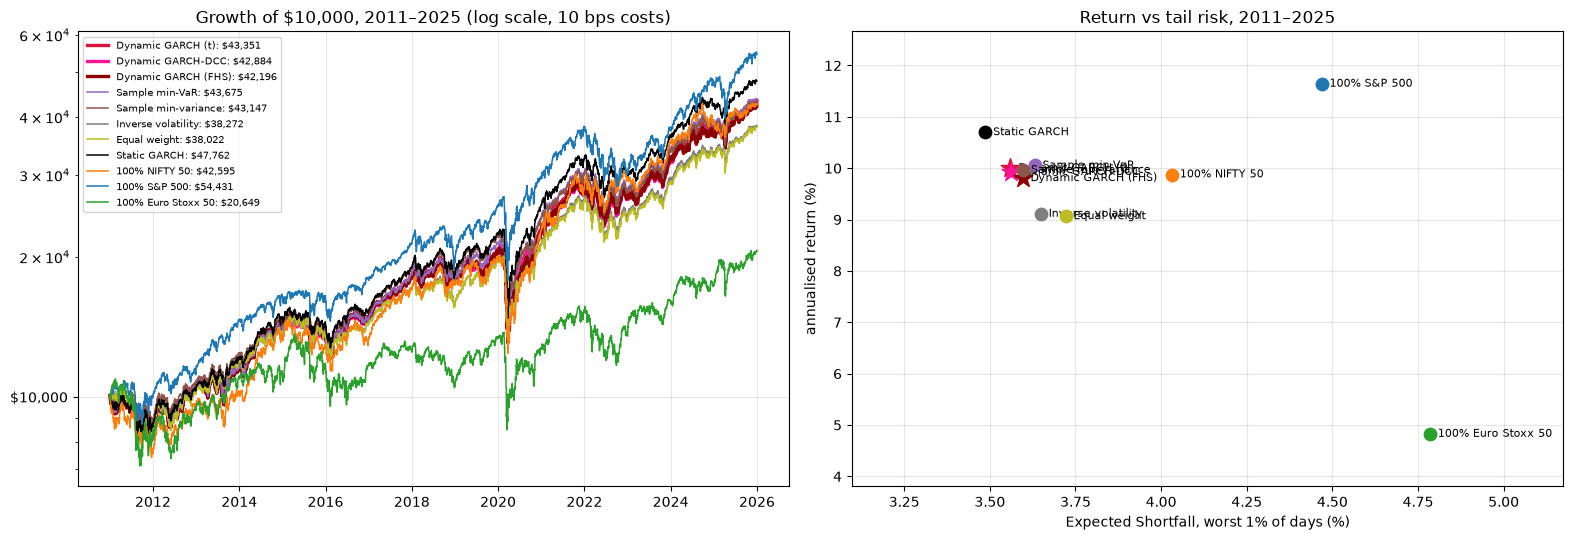

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for s in STRATS:
    v = runs[s]["value"]
    lw = 2.4 if s.startswith("Dynamic") else 1.1
    ax[0].plot(v.index, v, color=PALETTE[s], lw=lw, label=f"{s}: ${v.iloc[-1]:,.0f}")
    c = full[s]
    big = s.startswith("Dynamic")
    ax[1].scatter(100 * c["ES 1%"], 100 * c["Annualised return"], s=200 if big else 80,
                  marker="*" if big else "o", color=PALETTE[s], zorder=3)
    ax[1].annotate("  " + s, (100 * c["ES 1%"], 100 * c["Annualised return"]), fontsize=8, va="center")
ax[0].set_yscale("log"); ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[0].set_title(f"Growth of ${INITIAL_INVESTMENT:,}, 2011–2025 (log scale, {TC_BPS:.0f} bps costs)")
ax[0].legend(fontsize=7.5, loc="upper left")
ax[1].set_xlabel("Expected Shortfall, worst 1% of days (%)"); ax[1].set_ylabel("annualised return (%)")
ax[1].set_title("Return vs tail risk, 2011–2025"); ax[1].margins(x=0.3, y=0.15)
plt.tight_layout()

## 3. Test 2 — Is the portfolio VaR calibrated? t tail, DCC correlations, filtered historical simulation

Every strategy's daily returns are checked against all three VaR forecasts:

* **t-rolling:** Student-t tail, rolling 500-day correlation.
* **t-DCC:** Student-t tail, DCC correlations updated daily.
* **FHS:** filtered historical simulation. The expected breach rate is 1%. The Kupiec test checks the breach count and the Christoffersen test checks for clustering. A p-value below 0.05 means the VaR is rejected.

In [12]:
def kupiec_p(hits, p):
    n, x = len(hits), int(hits.sum())
    if x == 0: lr = -2 * n * np.log(1 - p)
    else:
        pi = x / n
        lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - pi) - x * np.log(pi))
    return 1 - stats.chi2.cdf(lr, 1)

def christoffersen_p(hits):
    h = hits.astype(int).values; a, b = h[:-1], h[1:]
    n00, n01 = ((a == 0) & (b == 0)).sum(), ((a == 0) & (b == 1)).sum()
    n10, n11 = ((a == 1) & (b == 0)).sum(), ((a == 1) & (b == 1)).sum()
    ll = lambda k, q: k * np.log(q) if k else 0.0
    pi0 = n01 / max(n00 + n01, 1); pi1 = n11 / max(n10 + n11, 1); pi = (n01 + n11) / max(len(a), 1)
    lr = -2 * ((ll(n00 + n10, 1 - pi) + ll(n01 + n11, pi)) -
               (ll(n00, 1 - pi0) + ll(n01, pi0) + ll(n10, 1 - pi1) + ll(n11, pi1)))
    return 1 - stats.chi2.cdf(lr, 1)

rows = []
for s in STRATS:
    df = runs[s]
    for tail, col in [("t-rolling", "VaR_t"), ("t-DCC", "VaR_dcc"), ("FHS", "VaR_fhs")]:
        hits = df["log_ret_pct"] < -df[col]
        rows.append({"strategy": s, "tail": tail, "days": len(df), "expected": round(len(df) * (1 - VAR_LEVEL), 1),
                     "breaches": int(hits.sum()), "rate": hits.mean(), "avg VaR (%)": df[col].mean(),
                     "Kupiec p": kupiec_p(hits, 1 - VAR_LEVEL), "Christoffersen p": christoffersen_p(hits)})
calib = pd.DataFrame(rows).set_index(["strategy", "tail"])
calib["passes both"] = (calib["Kupiec p"] > 0.05) & (calib["Christoffersen p"] > 0.05)
(calib.style
   .format({"rate": "{:.2%}", "avg VaR (%)": "{:.2f}", "Kupiec p": "{:.3f}", "Christoffersen p": "{:.3f}"})
   .map(lambda v: "color:#c0392b;font-weight:bold" if isinstance(v, float) and v < 0.05 else "",
        subset=["Kupiec p", "Christoffersen p"])
   .map(lambda v: "background-color:#d4edda" if bool(v) else "background-color:#f8d7da", subset=["passes both"]))

In [13]:
summary_cal = calib.groupby(level="tail").agg(pass_rate=("passes both", "mean"),
                                              mean_rate=("rate", "mean"))
print("Share of strategies whose VaR passes both tests, and average breach rate:")
summary_cal.style.format({"pass_rate": "{:.0%}", "mean_rate": "{:.2%}"})

Share of strategies whose VaR passes both tests, and average breach rate:


,pass_rate,mean_rate
tail,,
FHS,36%,1.03%
t-DCC,36%,1.19%
t-rolling,27%,1.24%


## 4. Test 3 — Walk-forward: rolling 3-year windows

The rebalanced strategies are evaluated on every 3-year window starting each January from 2011 to 2023 (13 overlapping windows). Static GARCH is **re-run from scratch** for each window: allocate at the window start using only data up to then, and hold for 3 years. Single-index returns do not depend on the start date.

For each window and each benchmark, we record whether Dynamic GARCH had lower volatility, lower ES, a smaller drawdown, a higher Sharpe ratio and a higher return.

13 windows, 17s


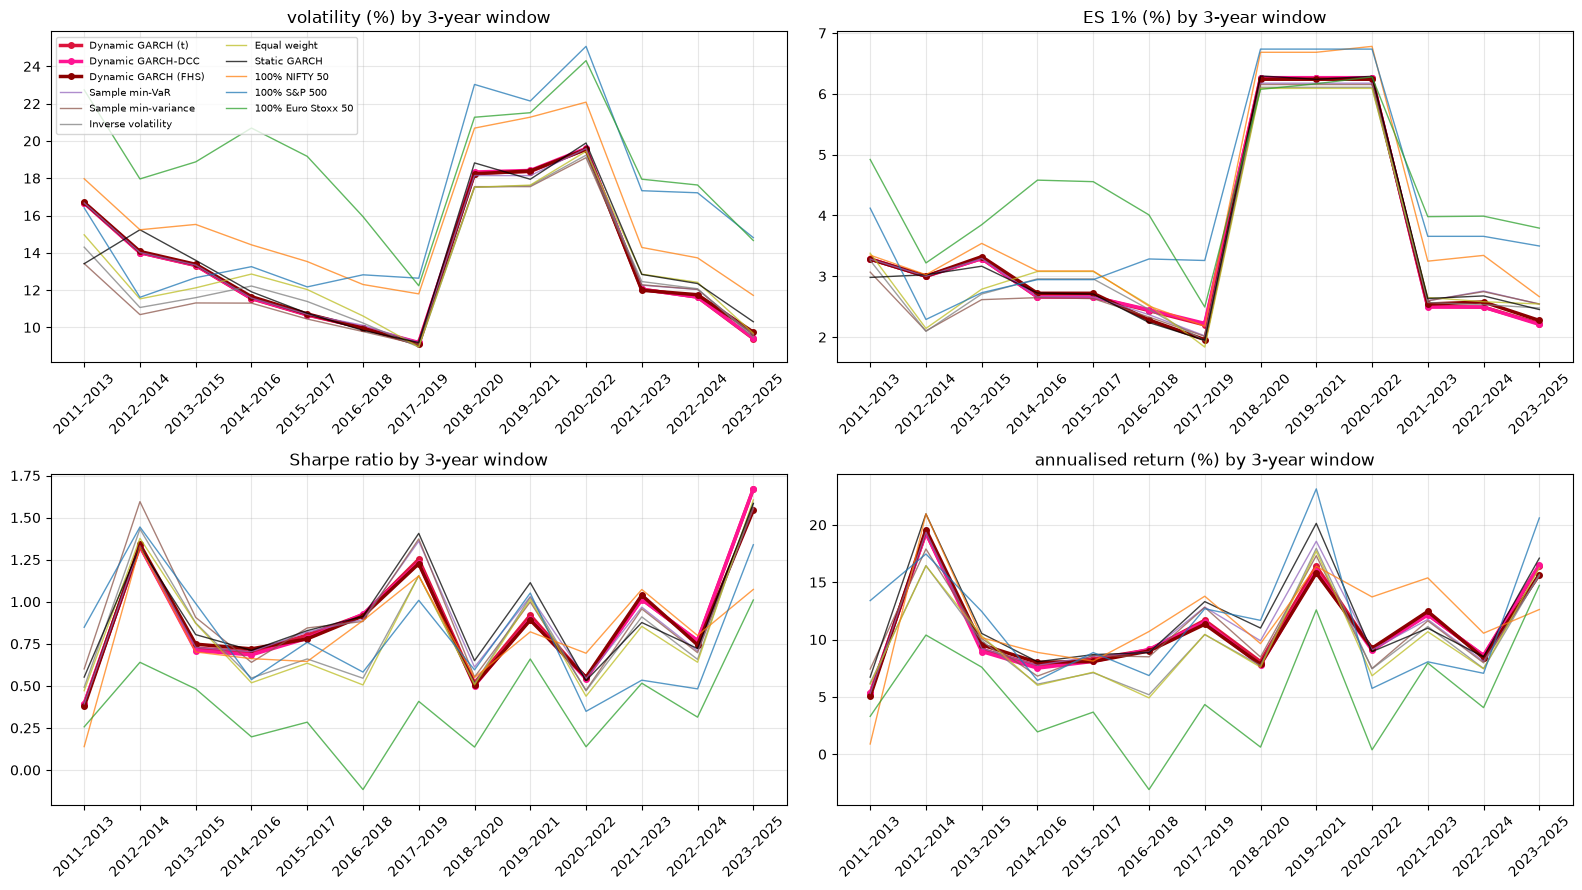

In [14]:
win_starts = [pd.Timestamp(f"{y}-01-01") for y in range(int(EVAL_START[:4]), P.index[-1].year - WF_YEARS + 2)]
wf_rows = []
static_wf = {}
t0 = time.time()
for s0 in win_starts:
    s1 = s0 + pd.DateOffset(years=WF_YEARS) - pd.Timedelta(days=1)
    st, _ = simulate(rule_garch_t, start=s0, end=min(s1, P.index[-1]), freq=None, horizon="full")
    static_wf[s0.year] = st["ret"]
    for s in STRATS:
        r = st["ret"] if s == "Static GARCH" else runs[s]["ret"]
        r = r[(r.index >= s0) & (r.index <= s1)]
        wf_rows.append({"window": f"{s0.year}–{s0.year + WF_YEARS - 1}", "strategy": s, **perf(r)})
wf = pd.DataFrame(wf_rows)
print(f"{len(win_starts)} windows, {time.time() - t0:.0f}s")

pivot = lambda m: wf.pivot(index="window", columns="strategy", values=m)[STRATS]
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
for a, (m, scale, lab) in zip(ax.flat, [("Annualised volatility", 100, "volatility (%)"),
                                       ("ES 1%", 100, "ES 1% (%)"),
                                       ("Sharpe (rf = 0)", 1, "Sharpe ratio"),
                                       ("Annualised return", 100, "annualised return (%)")]):
    pv = pivot(m) * scale
    for s in STRATS:
        lw = 2.5 if s.startswith("Dynamic") else 1
        a.plot(pv.index, pv[s], color=PALETTE[s], lw=lw, marker="o" if s.startswith("Dynamic") else None,
               ms=4, label=s, alpha=1 if s.startswith("Dynamic") else 0.75)
    a.set_title(f"{lab} by 3-year window"); a.tick_params(axis="x", rotation=45)
ax[0, 0].legend(fontsize=7.5, ncol=2)
plt.tight_layout()

In [15]:
def win_rates(hero):
    out = {}
    for s in STRATS:
        if s == hero: continue
        a = wf[wf.strategy == hero].set_index("window")
        b = wf[wf.strategy == s].set_index("window")
        out[s] = {
            "lower volatility": (a["Annualised volatility"] < b["Annualised volatility"]).mean(),
            "lower ES 1%": (a["ES 1%"] < b["ES 1%"]).mean(),
            "smaller drawdown": (a["Max drawdown"] > b["Max drawdown"]).mean(),
            "higher Sharpe": (a["Sharpe (rf = 0)"] > b["Sharpe (rf = 0)"]).mean(),
            "higher return": (a["Annualised return"] > b["Annualised return"]).mean(),
        }
    return pd.DataFrame(out).T

for hero in ["Dynamic GARCH (t)", "Dynamic GARCH-DCC", "Dynamic GARCH (FHS)"]:
    print(f"\nShare of the {len(win_starts)} windows in which {hero} beats each alternative:")
    display(win_rates(hero).style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))


Share of the 13 windows in which Dynamic GARCH (t) beats each alternative:


,lower volatility,lower ES 1%,smaller drawdown,higher Sharpe,higher return
Dynamic GARCH-DCC,92%,69%,54%,69%,69%
Dynamic GARCH (FHS),62%,54%,85%,62%,62%
Sample min-VaR,85%,62%,54%,38%,38%
Sample min-variance,23%,23%,38%,46%,54%
Inverse volatility,46%,46%,62%,69%,77%
Equal weight,46%,54%,69%,69%,77%
Static GARCH,77%,62%,62%,46%,31%
100% NIFTY 50,100%,92%,85%,69%,31%
100% S&P 500,77%,85%,38%,62%,46%
100% Euro Stoxx 50,100%,85%,100%,100%,100%



Share of the 13 windows in which Dynamic GARCH-DCC beats each alternative:


,lower volatility,lower ES 1%,smaller drawdown,higher Sharpe,higher return
Dynamic GARCH (t),8%,31%,46%,31%,31%
Dynamic GARCH (FHS),54%,54%,85%,54%,54%
Sample min-VaR,69%,54%,54%,31%,31%
Sample min-variance,23%,23%,38%,46%,54%
Inverse volatility,46%,46%,62%,62%,77%
Equal weight,46%,54%,69%,62%,77%
Static GARCH,69%,62%,62%,46%,31%
100% NIFTY 50,100%,92%,85%,69%,15%
100% S&P 500,77%,85%,38%,62%,46%
100% Euro Stoxx 50,100%,85%,100%,100%,100%



Share of the 13 windows in which Dynamic GARCH (FHS) beats each alternative:


,lower volatility,lower ES 1%,smaller drawdown,higher Sharpe,higher return
Dynamic GARCH (t),38%,46%,15%,38%,38%
Dynamic GARCH-DCC,46%,46%,15%,46%,46%
Sample min-VaR,38%,46%,38%,54%,62%
Sample min-variance,15%,38%,38%,38%,54%
Inverse volatility,38%,38%,62%,54%,69%
Equal weight,38%,54%,69%,54%,69%
Static GARCH,77%,54%,54%,46%,23%
100% NIFTY 50,100%,100%,85%,69%,15%
100% S&P 500,77%,85%,38%,62%,46%
100% Euro Stoxx 50,100%,85%,100%,100%,100%


**Rank of each strategy by risk.** The average rank across the windows (1 = lowest risk).

In [16]:
ranks = pd.DataFrame({m: pivot(m).rank(axis=1, ascending=True).mean() for m in
                      ["Annualised volatility", "ES 1%", "Realised 1% loss"]})
ranks["Max drawdown (rank)"] = (-pivot("Max drawdown")).rank(axis=1).mean()
ranks["Sharpe (rank, 1 = best)"] = pivot("Sharpe (rf = 0)").rank(axis=1, ascending=False).mean()
ranks.sort_values("Annualised volatility").style.format("{:.1f}").background_gradient(cmap="RdYlGn_r")

,Annualised volatility,ES 1%,Realised 1% loss,Max drawdown (rank),"Sharpe (rank, 1 = best)"
strategy,,,,,
Sample min-variance,2.2,3.5,3.8,4.5,4.5
Inverse volatility,3.8,3.8,5.0,5.5,6.2
Dynamic GARCH (t),3.9,4.7,4.0,4.5,4.7
Dynamic GARCH-DCC,5.1,5.1,4.1,4.6,5.4
Equal weight,5.1,5.2,6.7,6.0,7.2
Dynamic GARCH (FHS),5.3,5.1,4.6,5.8,5.4
Sample min-VaR,5.5,5.7,3.8,5.6,4.6
Static GARCH,6.3,5.5,5.3,5.4,4.0
100% S&P 500,8.9,8.8,9.3,4.8,6.3


## 5. Test 4 — Are the differences statistically significant?

**Method: paired circular block bootstrap.** The daily returns of two strategies over 2011–2025 are resampled **together**, in blocks of 20 consecutive days. Pairing keeps their correlation, and the blocks keep volatility clustering. For each of `N_BOOT` resamples the difference in each statistic is recomputed. Results are reported as:

* the observed difference,
* a 95% percentile confidence interval, and
* a one-sided bootstrap p-value: the share of resamples in which Dynamic GARCH is *not* better.

A difference is significant if its 95% interval excludes zero.

The Sharpe-ratio test follows the bootstrap approach of Ledoit & Wolf (2008), using a percentile rather than a studentised interval.

In [17]:
rng = np.random.default_rng(SEED)
common = runs["Dynamic GARCH (t)"].index
n = len(common)
n_blocks = int(np.ceil(n / BLOCK))
starts = rng.integers(0, n, size=(N_BOOT, n_blocks))
boot_idx = ((starts[:, :, None] + np.arange(BLOCK)[None, None, :]) % n).reshape(N_BOOT, -1)[:, :n]

def stats_matrix(R):
    # R: (N_BOOT, n) resampled daily returns -> dict of statistics per replication
    sd = R.std(axis=1, ddof=1)
    q = np.percentile(R, 100 * (1 - VAR_LEVEL), axis=1)
    es = -np.array([row[row <= qq].mean() for row, qq in zip(R, q)])
    return {"volatility": sd * np.sqrt(252), "ES 1%": es, "1% loss": -q,
            "Sharpe": R.mean(axis=1) / sd * np.sqrt(252), "return": R.mean(axis=1) * 252}

LOWER_BETTER = {"volatility", "ES 1%", "1% loss"}

def compare(hero, other):
    a = runs[hero]["ret"].reindex(common).values
    b = runs[other]["ret"].reindex(common).fillna(0).values
    A, B = stats_matrix(a[None, :]), stats_matrix(b[None, :])
    Ab, Bb = stats_matrix(a[boot_idx]), stats_matrix(b[boot_idx])
    rows = {}
    for k in A:
        diff = A[k][0] - B[k][0]
        db = Ab[k] - Bb[k]
        lo, hi = np.percentile(db, [2.5, 97.5])
        p = (db >= 0).mean() if k in LOWER_BETTER else (db <= 0).mean()
        rows[k] = {"dynamic": A[k][0], "other": B[k][0], "difference": diff, "CI low": lo, "CI high": hi,
                   "p (one-sided)": p, "significant": (hi < 0) if k in LOWER_BETTER else (lo > 0)}
    return pd.DataFrame(rows).T

t0 = time.time()
sig_rows = []
for hero in ["Dynamic GARCH (t)", "Dynamic GARCH-DCC", "Dynamic GARCH (FHS)", "Static GARCH"]:
    for other in STRATS:
        if other == hero or (hero.startswith("Dynamic") and other.startswith("Dynamic")): continue
        c = compare(hero, other)
        c.insert(0, "vs", other); c.insert(0, "strategy", hero)
        sig_rows.append(c)
sig = pd.concat(sig_rows).reset_index(names="statistic").set_index(["strategy", "vs", "statistic"])
print(f"bootstrap: {N_BOOT} replications × {len(sig_rows)} comparisons in {time.time() - t0:.0f}s")

bootstrap: 2000 replications × 34 comparisons in 4s


In [18]:
def show_sig(stat_list):
    t = sig[sig.index.get_level_values("statistic").isin(stat_list)].copy()
    pct = t.index.get_level_values("statistic") != "Sharpe"
    fmt_t = t.copy().astype(object)
    for c in ["dynamic", "other", "difference", "CI low", "CI high"]:
        fmt_t[c] = [f"{v:.2%}" if p else f"{v:+.2f}" if c in ("difference", "CI low", "CI high") else f"{v:.2f}"
                    for v, p in zip(t[c], pct)]
    fmt_t["p (one-sided)"] = t["p (one-sided)"].map("{:.3f}".format)
    fmt_t["significant"] = t["significant"].map(lambda v: "yes" if bool(v) else "no")
    return fmt_t.style.map(lambda v: "background-color:#d4edda;font-weight:bold" if v == "yes" else
                           "background-color:#f8d7da", subset=["significant"])

print("Risk: is Dynamic GARCH's volatility / tail loss significantly LOWER?")
show_sig(["volatility", "ES 1%"])

Risk: is Dynamic GARCH's volatility / tail loss significantly LOWER?


In [19]:
print("Reward: is Dynamic GARCH's Sharpe ratio / mean return significantly HIGHER?")
show_sig(["Sharpe", "return"])

Reward: is Dynamic GARCH's Sharpe ratio / mean return significantly HIGHER?


In [20]:
# compact scorecard
score = (sig.reset_index()
         .pivot_table(index=["strategy", "vs"], columns="statistic", values="significant", aggfunc="first")
         [["volatility", "ES 1%", "1% loss", "Sharpe", "return"]])
print("Significant at 5% (one-sided, block bootstrap):")
score.map(lambda v: "yes" if bool(v) else "no").style.map(
    lambda v: "background-color:#d4edda;font-weight:bold" if v == "yes" else "background-color:#f8d7da")

Significant at 5% (one-sided, block bootstrap):


## 6. The static portfolio under the same tests

The static strategy (Stage 3) makes one decision. At the start, it uses GARCH volatility forecasts for the *whole* holding period, training-period correlations and expected returns to choose the min-VaR mix for the target. It then never trades again. It is judged here on the same four criteria.

**How its allocation depends on the start date.** In the walk-forward test, the static portfolio is re-allocated at the start of each 3-year window using only data available then. The weights below show how sensitive that one-off decision is.

In [21]:
static_w = {}
for s0 in win_starts:
    d0 = P.index[P.index < s0][-1]
    s1 = min(s0 + pd.DateOffset(years=WF_YEARS) - pd.Timedelta(days=1), P.index[-1])
    w, feas = rule_garch_t(inputs_at(d0, P.index[P.index <= s1][-1]))
    static_w[f"{s0.year}–{s0.year + WF_YEARS - 1}"] = {**dict(zip(NAMES, w)), "target reachable": feas}
static_w = pd.DataFrame(static_w).T
sw_view = static_w.join(pivot("Annualised volatility")[["Static GARCH", "Equal weight", "Sample min-variance"]]
                        .add_prefix("vol: "))
sw_view = sw_view.join(pivot("Annualised return")[["Static GARCH", "Equal weight"]].add_prefix("return: "))
sw_view.style.format({**{n: "{:.0%}" for n in NAMES},
                      **{c: "{:.1%}" for c in sw_view.columns if c.startswith(("vol", "return"))}})

,NIFTY 50,S&P 500,Euro Stoxx 50,target reachable,vol: Static GARCH,vol: Equal weight,vol: Sample min-variance,return: Static GARCH,return: Equal weight
2011–2013,56%,44%,0%,True,13.4%,15.0%,13.4%,6.7%,6.1%
2012–2014,100%,0%,0%,False,15.2%,11.5%,10.7%,21.0%,16.4%
2013–2015,84%,16%,0%,True,13.6%,12.1%,11.3%,10.5%,10.3%
2014–2016,66%,34%,0%,True,11.9%,12.9%,11.3%,8.1%,6.0%
2015–2017,24%,76%,0%,True,10.8%,12.0%,10.4%,8.7%,7.2%
2016–2018,51%,49%,0%,True,9.8%,10.6%,9.8%,8.9%,4.9%
2017–2019,57%,43%,0%,True,9.2%,8.9%,9.1%,13.3%,10.4%
2018–2020,33%,67%,0%,True,18.8%,17.5%,17.5%,11.0%,7.6%
2019–2021,46%,54%,0%,True,17.9%,17.6%,17.5%,20.1%,17.7%
2020–2022,38%,62%,0%,True,19.9%,19.4%,19.1%,8.9%,6.8%


In [22]:
print("Share of the 13 windows in which Static GARCH beats each alternative:")
display(win_rates("Static GARCH").style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1))
print("\nBootstrap, 2011–2025 (Static GARCH allocated Dec 2010 and held): significant at 5%?")
st_score = score.loc["Static GARCH"] if "Static GARCH" in score.index.get_level_values(0) else None
st_score

Share of the 13 windows in which Static GARCH beats each alternative:


,lower volatility,lower ES 1%,smaller drawdown,higher Sharpe,higher return
Dynamic GARCH (t),23%,38%,38%,54%,69%
Dynamic GARCH-DCC,31%,38%,38%,54%,69%
Dynamic GARCH (FHS),23%,46%,46%,54%,77%
Sample min-VaR,31%,46%,54%,77%,77%
Sample min-variance,8%,38%,46%,62%,85%
Inverse volatility,31%,38%,54%,69%,92%
Equal weight,46%,46%,54%,77%,100%
100% NIFTY 50,92%,100%,85%,77%,54%
100% S&P 500,85%,85%,46%,77%,54%
100% Euro Stoxx 50,100%,77%,100%,100%,100%



Bootstrap, 2011–2025 (Static GARCH allocated Dec 2010 and held): significant at 5%?


statistic,volatility,ES 1%,1% loss,Sharpe,return
vs,,,,,
100% Euro Stoxx 50,True,True,True,True,False
100% NIFTY 50,True,True,True,False,False
100% S&P 500,True,True,True,False,False
Dynamic GARCH (FHS),True,False,False,False,False
Dynamic GARCH (t),True,False,True,False,False
Dynamic GARCH-DCC,True,False,True,False,False
Equal weight,True,True,True,False,False
Inverse volatility,False,False,True,False,False
Sample min-VaR,True,False,False,False,False


## 7. Verdict

The cell below gathers the evidence against the four criteria set out at the start. The written conclusion follows it.

In [23]:
for h in ["Dynamic GARCH (t)", "Dynamic GARCH-DCC", "Dynamic GARCH (FHS)", "Static GARCH"]:
    wr = win_rates(h)
    simple = [x for x in ["Equal weight", "Inverse volatility", "Sample min-variance", "Sample min-VaR"] if x != h]
    print(f"\n=== {h} ===")
    print(f"1. Benchmarks (2011–25): volatility {full.loc['Annualised volatility', h]:.2%} vs best simple rule "
          f"{full.loc['Annualised volatility', simple].min():.2%} ({full.loc['Annualised volatility', simple].idxmin()}); "
          f"ES {full.loc['ES 1%', h]:.2%} vs {full.loc['ES 1%', simple].min():.2%}")
    for tail in ["t-rolling", "t-DCC", "FHS"]:
        c = calib.loc[(h, tail)]
        print(f"2. VaR ({tail}): {c['breaches']} breaches vs {c['expected']} expected, Kupiec p={c['Kupiec p']:.3f}, "
              f"Christoffersen p={c['Christoffersen p']:.3f} -> {'PASS' if c['passes both'] else 'FAIL'}")
    print(f"3. Walk-forward: share of windows with lower volatility than each simple rule: "
          + ", ".join(f"{k} {wr.loc[k, 'lower volatility']:.0%}" for k in simple)
          + f"; higher Sharpe: " + ", ".join(f"{k} {wr.loc[k, 'higher Sharpe']:.0%}" for k in simple))
    s = sig.loc[h]
    nv = int(s.xs("volatility", level="statistic")["significant"].astype(bool).sum())
    ne = int(s.xs("ES 1%", level="statistic")["significant"].astype(bool).sum())
    ns_ = int(s.xs("Sharpe", level="statistic")["significant"].astype(bool).sum())
    tot = len(s.xs("volatility", level="statistic"))
    print(f"4. Significance (of {tot} comparisons): volatility significantly lower in {nv}, ES lower in {ne}, Sharpe higher in {ns_}")


=== Dynamic GARCH (t) ===
1. Benchmarks (2011–25): volatility 13.90% vs best simple rule 13.01% (Sample min-variance); ES 3.56% vs 3.60%
2. VaR (t-rolling): 57 breaches vs 38.8 expected, Kupiec p=0.006, Christoffersen p=0.001 -> FAIL
2. VaR (t-DCC): 53 breaches vs 38.8 expected, Kupiec p=0.030, Christoffersen p=0.006 -> FAIL
2. VaR (FHS): 44 breaches vs 38.8 expected, Kupiec p=0.409, Christoffersen p=0.014 -> FAIL
3. Walk-forward: share of windows with lower volatility than each simple rule: Equal weight 46%, Inverse volatility 46%, Sample min-variance 23%, Sample min-VaR 85%; higher Sharpe: Equal weight 69%, Inverse volatility 69%, Sample min-variance 46%, Sample min-VaR 38%
4. Significance (of 8 comparisons): volatility significantly lower in 3, ES lower in 3, Sharpe higher in 1

=== Dynamic GARCH-DCC ===
1. Benchmarks (2011–25): volatility 13.92% vs best simple rule 13.01% (Sample min-variance); ES 3.56% vs 3.60%
2. VaR (t-rolling): 58 breaches vs 38.8 expected, Kupiec p=0.004, Chr

### Verdict

**1. Benchmarks: neither dynamic version beats simple diversification, and DCC does not change that.**
2011–2025, after 10 bps trading costs:

| | Dyn. GARCH (t) | Dyn. GARCH-DCC | Sample min-VaR | Sample min-var. | Inverse vol. | Equal weight | **Static GARCH** |
|:--|--:|--:|--:|--:|--:|--:|--:|
| Volatility | 13.90% | 13.92% | 13.94% | **13.01%** | 13.37% | 13.72% | 13.08% |
| ES 1% | 3.56% | 3.56% | 3.63% | 3.60% | 3.65% | 3.72% | **3.49%** |
| Sharpe | 0.76 | 0.75 | 0.76 | 0.80 | 0.72 | 0.70 | **0.84** |
| Final value | $43,351 | $42,884 | $43,675 | $43,147 | $38,272 | $38,022 | **$47,762** |
| Monthly turnover | 15.1% | 15.4% | 5.1% | 2.2% | 4.0% | 0.9% | 0% |

- **The GARCH volatility forecast adds nothing to the allocation.** The same optimiser fed with a plain sample covariance (Sample min-VaR) reaches the same risk at a third of the turnover.
- **DCC adds nothing to the allocation either.** Dynamic GARCH-DCC is statistically indistinguishable from Dynamic GARCH (t). Its volatility was very slightly higher in 12 of 13 windows, by a few hundredths of a percentage point.

**2. Calibration: DCC and FHS both improve the VaR; only FHS fully fixes it for the dynamic portfolios.**

| Tail model | Strategies passing both tests | Average breach rate (target 1%) |
|:--|--:|--:|
| t, rolling correlation | 3 of 11 | 1.24% |
| t, DCC correlation | 4 of 11 | 1.19% |
| FHS | 4 of 11 | **1.03%** |

- **DCC reduces breaches for every rebalanced portfolio.** For example, Dynamic GARCH (t) falls from 57 to 53, and Equal weight passes with p = 0.72 and 0.46.
- **DCC is not enough for the dynamic portfolios.** They still fail the t-DCC test, because the t tail is too thin.
- **FHS is the best tail model,** with an average breach rate of 1.03% against 1.19–1.24% for the t-based versions. Dynamic GARCH (FHS) passes both tests.

**3–4. Walk-forward and significance.** Every diversified strategy is significantly less risky than any single market (p ≤ 0.001). Against each other:
- **Dynamic GARCH, with or without DCC, ranks mid-table on risk.**
- **Its volatility is significantly *higher*** than sample minimum variance and static GARCH.
- **No Sharpe-ratio difference between the diversified strategies is significant.**

### The static portfolio as a strategy

The static portfolio holds up better than the dynamic one on almost every test:

| Test | Static GARCH result |
|:--|:--|
| **Benchmarks** (2011–25) | Lowest ES (3.49%) and highest Sharpe (0.84) and final value ($47,762) of all diversified strategies. Its volatility (13.08%) is statistically tied with the best, sample min-variance (13.01%). It never trades, so it has no costs. |
| **Calibration** | The **only** portfolio strategy whose VaR passes both tests under all three tail models: 38–40 breaches against 38.8 expected. A buy-and-hold mix of two indices has a stable composition, so its risk is easier to model than a portfolio whose weights change every month. |
| **Walk-forward** | Lower volatility than 100% NIFTY in 92% of windows and than 100% S&P in 85%. Higher return than equal weight in **every** window and higher Sharpe in 77%. However, it had lower volatility than sample min-variance in only 8% and than equal weight in 46%. It earns its Sharpe advantage through return, not through lower risk. |
| **Significance** | Volatility significantly lower than all three dynamic strategies, sample min-VaR and equal weight. ES significantly lower than equal weight. No Sharpe difference is significant except against 100% Euro Stoxx. |

**Why it works.** The static strategy's value comes from **one structural decision rather than from timing**:
- **It never holds the Euro Stoxx 50.** The Euro Stoxx weight is 0% at every one of the 13 window starts, because it combines the highest volatility, the lowest expected return and a high correlation with the S&P 500.
- **It splits the money between the NIFTY 50 and the S&P 500,** which have the lowest correlation of any pair (about 0.24). That split provides most of the diversification.
- **The Euro Stoxx 50 then returned the least** (4.8% a year over 2011–2025), so excluding it helped both risk and return.

**Where it is fragile.**
- **The NIFTY/S&P split depends heavily on the start date:** from 24% to 100% NIFTY across the 13 windows.
- **This sensitivity comes from the expected-return estimates,** which are noisy, not from the risk model.
- **At least once the target couldn't be reached:** at the 2012–2014 window start, the return target was above every index's estimated return, so the rule fell back to 100% NIFTY. That window had 15.2% volatility against 11.5% for equal weight.
- **In practice,** the static rule needs a sensible cap on any single market, or a periodic (for example annual) review, rather than blind holding.

### Conclusion

> **Viable:** a diversified minimum-risk allocation across these markets. Both the static and dynamic versions significantly reduce risk compared with any single market, consistently across periods.
>
> **Best construction:** the **static** GARCH allocation, or a plain sample minimum-variance portfolio. Each matched or beat the monthly dynamic strategies on risk and on risk-adjusted return, with little or no trading. The static portfolio's VaR is also the best calibrated of any strategy.
>
> **What GARCH and DCC contribute:** *risk measurement*, not allocation. GJR-GARCH volatilities with DCC correlations make the daily VaR react to volatility and correlation spikes, removing breach clustering. A filtered-historical-simulation tail then brings the breach rate to its target.

**Caveats.**
- The windows overlap.
- Many comparisons were run, so some significant results may arise by chance.
- The evaluation starts in 2011.
- The static strategy's 15-year result depends on one allocation decision made in December 2010, which is why the walk-forward re-allocation matters.